# 23. Merge k Sorted Lists
**Difficulty:** 🔴 Hard · **Topic:** Heap · **Pattern:** [K Way Merge](README.md) · **LeetCode:** https://leetcode.com/problems/merge-k-sorted-lists/

## 💡 Concepts

**Core concept(s):** Repeatedly take the smallest head across all lists — fast with a **min-heap**.

**Why it applies here:** With k sorted lists, the next node in the merged list is the smallest of the k current heads. A heap always surfaces that minimum in O(log k), so each of the N nodes costs O(log k).

**Key intuition:** Keep the k front nodes in a heap; pop the smallest, push its successor.

---

### 📚 What is a Linked List?
A **linked list** is a chain of nodes; each node holds a value and a pointer to the **next** node. Unlike an array there is no index — you can only walk forward from the head.
- **In Python:** a small `ListNode` class with `.val` and `.next`.

### 📚 What is a Heap (Priority Queue)?
A **min-heap** always hands you its smallest item in **O(log n)**. Perfect for repeatedly taking the current minimum across many sources.
- **In Python:** `heapq` on a list.

### 📚 Pointers & the Dummy Node
Linked-list code moves **pointers** (references to nodes). A **dummy** node placed before the head removes annoying "is this the first node?" special cases — you build off `dummy.next` and return it at the end.

---

**Prerequisite knowledge:**
- Heaps (`heapq`).
- Merging sorted sequences.

## 📝 Problem

You are given an array of `k` linked lists, each sorted in ascending order. Merge them into one sorted linked list and return its head.

**Example 1**
```
lists = [[1,4,5], [1,3,4], [2,6]]  ->  [1,1,2,3,4,4,5,6]
```

**Example 2**
```
lists = []    ->  []
lists = [[]]  ->  []
```

**Constraints:** `0 <= k <= 10^4`, `0 <= lists[i].length <= 500`, `-10^4 <= lists[i][j] <= 10^4`, each list is sorted ascending, total nodes `N <= 10^4`.

> Two approaches: collect-and-sort `O(N log N)` and heap `O(N log k)`.

In [1]:
from typing import Optional, List

class ListNode:
    """A node in a singly linked list: a value plus a link to the next node."""
    def __init__(self, val=0, next=None):
        self.val = val                     # the value stored at this node
        self.next = next                   # link to the next node (None at the end)

def build_list(vals):
    """Turn a Python list into a linked list; return its head."""
    dummy = ListNode(); cur = dummy        # dummy node avoids special-casing the first node
    for v in vals:
        cur.next = ListNode(v); cur = cur.next
    return dummy.next

def to_list(head):
    """Turn a linked list back into a Python list (handy for printing / assertions)."""
    out = []
    while head:
        out.append(head.val); head = head.next
    return out

### Approach 1 — Collect & Sort (worst)

**Idea:** Dump all values into an array, sort, rebuild a list.

**Time:** `O(N log N)`. **Space:** `O(N)`.

In [2]:
def merge_k_brute(lists):
    vals = []
    for node in lists:                     # collect every value from every list
        while node:
            vals.append(node.val); node = node.next
    vals.sort()                            # sort them all together
    dummy = ListNode(); cur = dummy        # rebuild one sorted linked list
    for v in vals:
        cur.next = ListNode(v); cur = cur.next
    return dummy.next

### Approach 2 — Min-Heap (optimal)

**Idea:** Push each list's head into a heap. Pop the smallest, append it, and push its next node. The heap entry is `(val, i, node)`: when two values are equal, the list index `i` breaks the tie, so Python never has to compare two `ListNode` objects (it can't: `ListNode` defines no `<`, and a bare `(val, node)` raises `TypeError` on the first tie — the correctness check shows it).

**Time:** `O(N log k)`. **Space:** `O(k)`.

In [3]:
import heapq

def merge_k_heap(lists):
    heap = []                              # min-heap of the current front node of each list
    for i, node in enumerate(lists):
        if node:
            heapq.heappush(heap, (node.val, i, node))  # (value, list-index tiebreak, node)
    dummy = ListNode(); cur = dummy
    while heap:
        val, i, node = heapq.heappop(heap) # smallest available value across all lists
        cur.next = node; cur = node        # attach it to the merged list
        if node.next:
            heapq.heappush(heap, (node.next.val, i, node.next))  # push that list's next node
    return dummy.next

In [4]:
# Correctness check
lists = [build_list([1,4,5]), build_list([1,3,4]), build_list([2,6])]
lists2 = [build_list([1,4,5]), build_list([1,3,4]), build_list([2,6])]
assert to_list(merge_k_brute(lists)) == [1,1,2,3,4,4,5,6]
assert to_list(merge_k_heap(lists2)) == [1,1,2,3,4,4,5,6]
assert to_list(merge_k_heap([])) == []
assert to_list(merge_k_heap([None])) == [] and to_list(merge_k_brute([None])) == []   # lists = [[]]
assert to_list(merge_k_heap([build_list([2]), None, build_list([1, 3])])) == [1, 2, 3]

# Why the heap entry needs the index tie-breaker: without it, equal values make Python compare ListNodes
try:
    h = []
    heapq.heappush(h, (1, ListNode(1)))
    heapq.heappush(h, (1, ListNode(1)))   # tie on 1 -> compares ListNode < ListNode
    raise AssertionError("expected a TypeError")
except TypeError as e:
    print("(val, node) without a tie-breaker fails:", e)
print("All tests passed")

(val, node) without a tie-breaker fails: '<' not supported between instances of 'ListNode' and 'ListNode'
All tests passed


## ⏱️ Empirically Checking the Complexities

We time each approach on inputs of growing size `n` and read the **doubling ratio**.

| Theoretical | Ratio when `n` → `2n` |
|---|---|
| `O(n)`       | ≈ **2×** |
| `O(n log n)` | ≈ **2×** (slightly more) |
| `O(n²)`     | ≈ **4×** |

**Input:** `k = 10` lists, `N` nodes dealt round-robin (list `i` holds `i, i+10, i+20, ...`), so every pop and push of the heap is real work and no list runs out early.

**What to expect, honestly:**
- With `k` fixed, `O(N log k)` is linear in `N` → the heap should show ≈2×.
- Collect & sort is `O(N log N)` in theory, which also reads as ≈2× (slightly more): the doubling ratio cannot tell `N log N` from `N log k` apart.
- Python's sort (Timsort) also detects the `k` already-sorted runs in the collected array and merges them, so here it behaves like `O(N log k)` too, and it runs in C. Expect the brute force to be competitive or faster on wall-clock time.
- The heap's real advantages are the guarantee (no reliance on run detection), `O(k)` extra space instead of `O(N)`, and that it can stop early or work on streams.


collect+sort O(N log N)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     8000 |       0.79 |           n/a
    16000 |       1.59 |         2.00x
    32000 |       3.40 |         2.14x
    64000 |       6.49 |         1.91x

heap        O(N log k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     8000 |       0.74 |           n/a
    16000 |       1.57 |         2.13x
    32000 |       3.20 |         2.04x
    64000 |       6.01 |         1.88x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


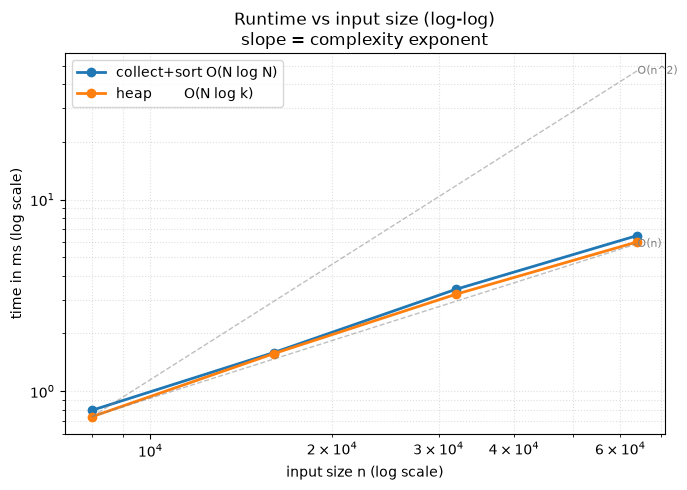

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")): break
    _root = os.path.dirname(_root)
if _root not in sys.path: sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    k = 10
    lists = [build_list(list(range(i, n, k))) for i in range(k)]
    return (lists,)
solutions = {
    "collect+sort O(N log N)": merge_k_brute,
    "heap        O(N log k)": merge_k_heap,
}
sizes = [8000, 16000, 32000, 64000]

# repeats must stay 1: merge_k_heap relinks the input nodes, so a second run on the same lists would loop.
# The brute force allocates N new nodes, which triggers garbage-collection pauses that swamp the ratios;
# switch GC off while timing, as Python's timeit does by default.
import gc
gc.disable()
try:
    benchmark(solutions, make_worst_case, sizes, plot=True)
finally:
    gc.enable()


## 🧩 Patterns Learned

- **Pattern:** [K Way Merge](README.md) — the template itself: a min-heap holds one `(val, list_index, node)` entry per list; pop the smallest, append it, push that list's next node.
- **Heap to merge many sorted sources:** always pull the global minimum in O(log k).
- **Tie-break tuple:** add an index so the heap never compares the payload objects.
- **Signal:** "merge k sorted ...", "k-way merge", "smallest across k streams".
- **Related problems:** Merge Two Sorted Lists, Kth Smallest in Sorted Matrix, Smallest Range Covering k Lists.
- **Common pitfalls:** (1) heap comparing nodes (add a tiebreaker); (2) forgetting to push the successor.